# Análise exploratória: internações por município (AIH/SIH)

Base: `data/processed/aih_municipio_tratado.csv`, com as internações mensais por município de jan/2008 a set/2026.

Cada seção termina com **o que fazer com isso**. O foco é entender onde a demanda se concentra e quais municípios merecem atenção.

> A base só traz os municípios que aparecem no arquivo original (cerca de 3.600, e não os 5.570 do país). Os municípios aparecem pelo município de **internação**, não pelo de residência do paciente.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (11, 4)
MESES = ["jan", "fev", "mar", "abr", "mai", "jun", "jul", "ago", "set", "out", "nov", "dez"]

## 1. Dados e qualidade

In [2]:
mu = pd.read_csv("../../data/processed/aih_municipio_tratado.csv", parse_dates=["data"])
# há municípios com o mesmo nome em UFs diferentes: nome + UF identifica cada um
mu["municipio"] = mu["municipio"].str.title() + " (" + mu["uf"] + ")"
print(mu.shape, "| período:", mu["data"].min().date(), "a", mu["data"].max().date())
print("Municípios:", mu["municipio"].nunique(), "=", mu["codigo_municipio"].nunique(), "códigos | UFs:", mu["uf"].nunique())
print(f"Células com valor 0: {(mu['valor'] == 0).mean() * 100:.1f}%")
mu.head()

(814275, 6) | período: 2008-01-01 a 2026-09-01
Municípios: 3619 = 3619 códigos | UFs: 27
Células com valor 0: 14.8%


,codigo_municipio,municipio,codigo_uf,uf,data,valor
0,110001,Alta Floresta D'Oeste (RO),11,RO,2008-01-01,176
1,110001,Alta Floresta D'Oeste (RO),11,RO,2008-02-01,189
2,110001,Alta Floresta D'Oeste (RO),11,RO,2008-03-01,190
3,110001,Alta Floresta D'Oeste (RO),11,RO,2008-04-01,190
4,110001,Alta Floresta D'Oeste (RO),11,RO,2008-05-01,189


Mais de uma em cada dez células é zero (eram `-` no original). No município isso costuma ser mês sem internação, e não dado ausente, então os zeros ficam. O que preocupa é o **último mês**: veja quantos municípios registraram internação em cada mês.

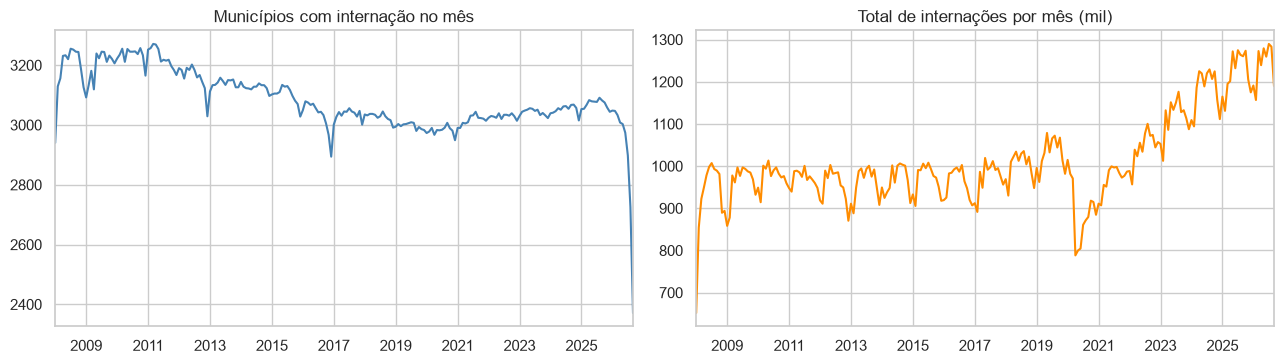

{Timestamp('2026-06-01 00:00:00'): 2974, Timestamp('2026-07-01 00:00:00'): 2898, Timestamp('2026-08-01 00:00:00'): 2725, Timestamp('2026-09-01 00:00:00'): 2371}


In [3]:
ativos = mu[mu["valor"] > 0].groupby("data")["municipio"].nunique()
total = mu.groupby("data")["valor"].sum()

fig, eixos = plt.subplots(1, 2, figsize=(13, 3.8))
ativos.plot(ax=eixos[0], color="steelblue")
eixos[0].set_title("Municípios com internação no mês")
total.div(1e3).plot(ax=eixos[1], color="darkorange")
eixos[1].set_title("Total de internações por mês (mil)")
for ax in eixos:
    ax.set_xlabel("")
plt.tight_layout()
plt.show()
print(ativos.tail(4).to_dict())

Em ago e set/2026 há bem menos municípios ativos: os últimos meses ainda estão incompletos (municípios pequenos costumam enviar com atraso). Nas análises a seguir usamos dados até jul/2026.

In [4]:
mu = mu[mu["data"] < "2026-08-01"].copy()
mu["ano"] = mu["data"].dt.year
print("Último mês:", mu["data"].max().date())

Último mês: 2026-07-01


## 2. Concentração das internações (2025)

Municípios com registro em 2025: 3619
Top   10: 20.7% das internações
Top   50: 40.1% das internações
Top  100: 50.7% das internações
Top  300: 69.9% das internações
Top 1000: 90.3% das internações
Municípios necessários para 50%: 96


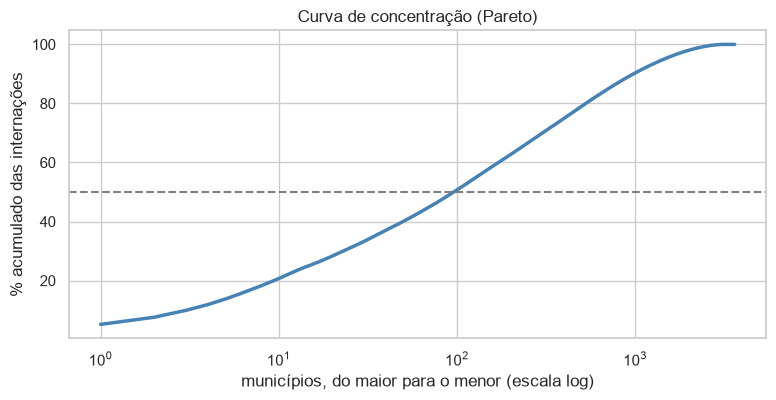

,municipio,uf,valor,pct
0,Sao Paulo (SP),SP,757113,5.2
1,Rio De Janeiro (RJ),RJ,355141,2.4
2,Recife (PE),PE,337648,2.3
3,Belo Horizonte (MG),MG,290439,2.0
4,Salvador (BA),BA,271936,1.9
5,Brasilia (DF),DF,248744,1.7
6,Fortaleza (CE),CE,224184,1.5
7,Curitiba (PR),PR,194424,1.3
8,Porto Alegre (RS),RS,183739,1.3
9,Goiania (GO),GO,167807,1.1


In [5]:
vol = (mu[mu["ano"] == 2025].groupby(["municipio", "uf"])["valor"].sum()
       .sort_values(ascending=False).reset_index())
vol["pct"] = vol["valor"] / vol["valor"].sum() * 100
vol["acumulado"] = vol["pct"].cumsum()

n = len(vol)
print(f"Municípios com registro em 2025: {n}")
for k in (10, 50, 100, 300, 1000):
    print(f"Top {k:>4}: {vol['acumulado'].iloc[k - 1]:.1f}% das internações")
print("Municípios necessários para 50%:", (vol["acumulado"] < 50).sum() + 1)

fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(np.arange(1, n + 1), vol["acumulado"], color="steelblue", linewidth=2.5)
ax.axhline(50, color="gray", linestyle="--")
ax.set_xscale("log")
ax.set_xlabel("municípios, do maior para o menor (escala log)")
ax.set_ylabel("% acumulado das internações")
ax.set_title("Curva de concentração (Pareto)")
plt.show()

vol.head(12)[["municipio", "uf", "valor", "pct"]].round(1)

**O que vemos.** A demanda é muito concentrada: 96 municípios respondem por 50% das internações de 2025. O top 10 soma 20,7%, o top 100 soma 50,7%, o top 300 soma 69,9% e o top 1.000 soma 90,3%. Só São Paulo tem 5,2% do total.

**O que fazer com isso.** Monitorar cerca de 100 municípios cobre metade da demanda do país. O restante é pulverizado e pede gestão regional.

## 3. Municípios sem internações

472 de 3619 municípios (13.0%) sem nenhuma internação em 2025


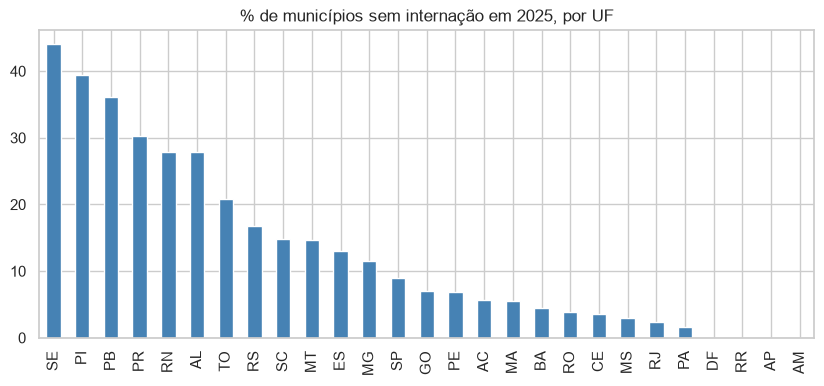

,sum,count,% sem internação
uf,,,
SE,11,25,44.0
PI,41,104,39.4
PB,35,97,36.1
PR,88,291,30.2
RN,34,122,27.9
AL,15,54,27.8
TO,10,48,20.8
RS,46,275,16.7


In [6]:
por_municipio = mu.groupby(["municipio", "uf", "ano"])["valor"].sum().unstack()
registrados = por_municipio[2025].dropna()
sem = registrados[registrados == 0]
print(f"{len(sem)} de {len(registrados)} municípios ({len(sem) / len(registrados) * 100:.1f}%) sem nenhuma internação em 2025")

por_uf = (registrados.reset_index()
          .assign(sem=lambda d: d[2025] == 0)
          .groupby("uf")["sem"].agg(["sum", "count"]))
por_uf["% sem internação"] = (por_uf["sum"] / por_uf["count"] * 100).round(1)
por_uf = por_uf.sort_values("% sem internação", ascending=False)

fig, ax = plt.subplots(figsize=(10, 4))
por_uf["% sem internação"].plot.bar(ax=ax, color="steelblue")
ax.set_title("% de municípios sem internação em 2025, por UF")
ax.set_xlabel("")
plt.show()
por_uf.head(8)

**O que vemos.** 472 dos 3.619 municípios (13,0%) não tiveram nenhuma internação registrada em 2025. A proporção é alta em Sergipe (44,0%), Piauí (39,4%), Paraíba (36,1%) e Paraná (30,2%).

**O que fazer com isso.** Isso não significa ausência de doença: a base usa o município onde o paciente foi **internado**, então esses municípios provavelmente não têm leito SUS próprio e seus moradores se deslocam. Antes de decidir investimentos, mapear o fluxo por município de residência.

## 4. Perfil por porte

Agrupamos os municípios pelo total de internações em 2025.

In [7]:
faixas = [-1, 0, 1_000, 10_000, 50_000, np.inf]
nomes = ["sem internação", "até 1 mil", "1 a 10 mil", "10 a 50 mil", "mais de 50 mil"]
porte = pd.cut(registrados, bins=faixas, labels=nomes)

resumo = pd.DataFrame({
    "municípios": porte.value_counts().reindex(nomes),
    "% dos municípios": (porte.value_counts(normalize=True).reindex(nomes) * 100).round(1),
    "% das internações": (registrados.groupby(porte, observed=False).sum() / registrados.sum() * 100).round(1),
})
resumo

,municípios,% dos municípios,% das internações
2025,,,
sem internação,472,13.0,0.0
até 1 mil,1608,44.4,4.4
1 a 10 mil,1279,35.3,28.3
10 a 50 mil,221,6.1,30.5
mais de 50 mil,39,1.1,36.8


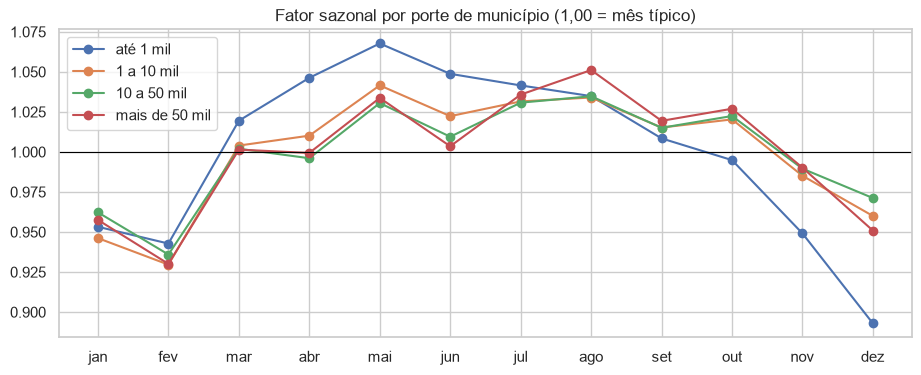

até 1 mil         17.5
1 a 10 mil        11.2
10 a 50 mil        9.9
mais de 50 mil    12.1
Name: amplitude (pp), dtype: float64

In [8]:
porte_por_municipio = porte.reset_index().rename(columns={2025: "porte"}).drop_duplicates("municipio").set_index("municipio")["porte"]
mu["porte"] = mu["municipio"].map(porte_por_municipio)

# sazonalidade em cada faixa de porte (2012 a 2025, sem 2020 e 2021)
anos_ok = [a for a in range(2012, 2026) if a not in (2020, 2021)]
saz = {}
for faixa in nomes[1:]:
    serie = mu[(mu["porte"] == faixa) & mu["ano"].isin(anos_ok)].groupby("data")["valor"].sum()
    relativa = serie / serie.groupby(serie.index.year).transform("mean")
    saz[faixa] = relativa.groupby(relativa.index.month).mean()
saz = pd.DataFrame(saz)

fig, ax = plt.subplots()
saz.plot(ax=ax, marker="o")
ax.set_xticks(range(1, 13))
ax.set_xticklabels(MESES)
ax.axhline(1, color="black", linewidth=0.8)
ax.set_xlabel("")
ax.set_title("Fator sazonal por porte de município (1,00 = mês típico)")
plt.show()
((saz.max() - saz.min()) * 100).round(1).rename("amplitude (pp)")

**O que vemos.** 39 municípios (1,1%) com mais de 50 mil internações respondem por 36,8% do total, enquanto os 44,4% de municípios com até 1 mil respondem por apenas 4,4%. Os menores têm mais oscilação sazonal (17,5 pp) que os maiores (9,9 a 12,1 pp).

**O que fazer com isso.** Municípios pequenos precisam de capacidade flexível e apoio regional. Os grandes precisam de capacidade estruturada e planejada para os meses de pico.

## 5. Crescimento dos maiores municípios (2019 a 2025)

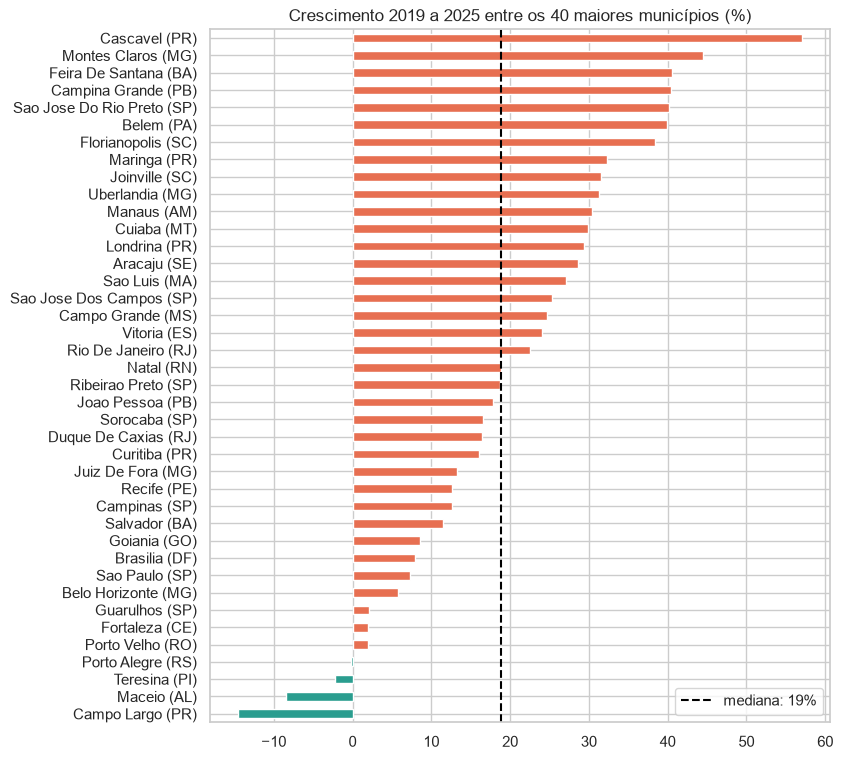

(municipio
 Belem (PA)                    39.9
 Sao Jose Do Rio Preto (SP)    40.2
 Campina Grande (PB)           40.5
 Feira De Santana (BA)         40.6
 Montes Claros (MG)            44.5
 Cascavel (PR)                 57.0
 dtype: float64,
 municipio
 Campo Largo (PR)    -14.5
 Maceio (AL)          -8.5
 Teresina (PI)        -2.2
 Porto Alegre (RS)    -0.2
 Porto Velho (RO)      1.9
 Fortaleza (CE)        2.0
 dtype: float64)

In [9]:
grandes = vol.head(40)
anual = por_municipio.loc[list(zip(grandes["municipio"], grandes["uf"]))]
anual.index = anual.index.get_level_values("municipio")
cresc = ((anual[2025] / anual[2019] - 1) * 100).dropna().sort_values()

fig, ax = plt.subplots(figsize=(8, 9))
cores = ["#e76f51" if v > 0 else "#2a9d8f" for v in cresc]
cresc.plot.barh(ax=ax, color=cores)
ax.axvline(cresc.median(), color="black", linestyle="--", label=f"mediana: {cresc.median():.0f}%")
ax.set_title("Crescimento 2019 a 2025 entre os 40 maiores municípios (%)")
ax.set_ylabel("")
ax.legend()
plt.show()
cresc.round(1).tail(6), cresc.round(1).head(6)

**O que vemos.** Entre os 40 maiores municípios, os que mais cresceram de 2019 a 2025 foram Cascavel (+57,0%), Montes Claros (+44,5%), Feira de Santana (+40,6%), Campina Grande (+40,5%), São José do Rio Preto (+40,2%) e Belém (+39,9%). Campo Largo (-14,5%) e Maceió (-8,5%) caíram. Fortaleza e Porto Alegre ficaram praticamente estáveis.

**O que fazer com isso.** Cidades polo que crescem muito tendem a atender a região inteira e sinalizam sobrecarga. Elas são candidatas a reforço de capacidade e a integração com os municípios vizinhos.

## 6. Peso do maior município dentro da UF

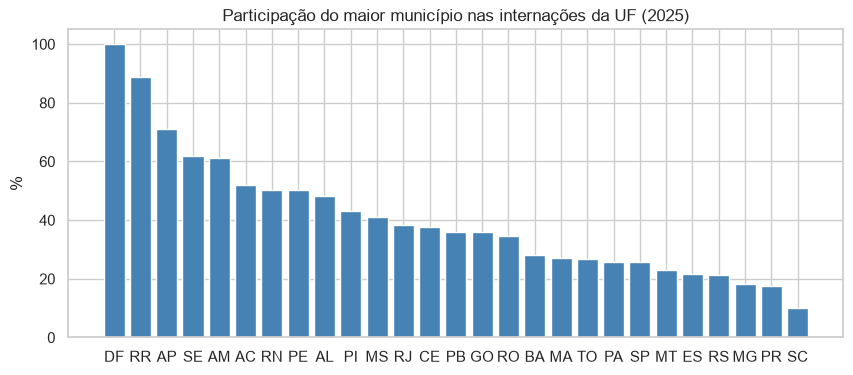

,municipio,% da UF
uf,,
DF,Brasilia (DF),100.0
RR,Boa Vista (RR),88.7
AP,Macapa (AP),71.2
SE,Aracaju (SE),61.7
AM,Manaus (AM),61.2
AC,Rio Branco (AC),52.0
RN,Natal (RN),50.4
PE,Recife (PE),50.2
AL,Maceio (AL),48.1


In [10]:
uf_total = mu[mu["ano"] == 2025].groupby("uf")["valor"].sum()
maior = (mu[mu["ano"] == 2025].groupby(["uf", "municipio"])["valor"].sum()
         .reset_index().sort_values("valor", ascending=False).drop_duplicates("uf").set_index("uf"))
maior["% da UF"] = (maior["valor"] / uf_total * 100).round(1)
maior = maior.sort_values("% da UF", ascending=False)

fig, ax = plt.subplots(figsize=(10, 4))
ax.bar(maior.index, maior["% da UF"], color="steelblue")
ax.set_title("Participação do maior município nas internações da UF (2025)")
ax.set_ylabel("%")
plt.show()
maior[["municipio", "% da UF"]]

**O que vemos.** A capital concentra a maior parte das internações em vários estados: Boa Vista 88,7% de Roraima, Macapá 71,2%, Aracaju 61,7%, Manaus 61,2% e Rio Branco 52,0%. (O Distrito Federal é um único município.) No outro extremo, Florianópolis tem 10,0% de SC, Belo Horizonte 18,2% de MG e Curitiba 17,7% do PR.

**O que fazer com isso.** Estados com capital dominante dependem muito de uma cidade: uma falha ali afeta o estado inteiro. Onde a oferta é distribuída, a gestão precisa ser regional.

## 7. Quedas e saltos atípicos

Procuramos municípios de médio e grande porte com meses fora do padrão (muito abaixo ou acima da mediana dos 12 meses anteriores). Pode ser problema de cadastro ou de envio de dados, ou mudança real, como fechamento de leitos.

In [11]:
grandes_mu = registrados[registrados > 3_000].index.get_level_values("municipio")
pivo = (mu[mu["municipio"].isin(grandes_mu)]
        .pivot_table(index="data", columns="municipio", values="valor", aggfunc="sum"))
referencia = pivo.rolling(12).median().shift(1)
razao = pivo / referencia

quedas = razao.stack().loc[lambda s: s < 0.4].reset_index()
quedas.columns = ["data", "municipio", "razao"]
quedas = quedas[quedas["data"].dt.year >= 2015]
print("Municípios grandes analisados:", pivo.shape[1])
print("Ocorrências de mês < 40% do normal (desde 2015):", len(quedas), "em", quedas["municipio"].nunique(), "municípios")
quedas.groupby("municipio").size().sort_values(ascending=False).head(8)

Municípios grandes analisados: 772
Ocorrências de mês < 40% do normal (desde 2015): 877 em 251 municípios


municipio
Coracao De Maria (BA)          31
Belford Roxo (RJ)              20
Sombrio (SC)                   19
Jaragua (GO)                   17
Nova Veneza (SC)               16
Barra De Sao Francisco (ES)    16
Nilopolis (RJ)                 15
Faxinal (PR)                   14
dtype: int64

In [12]:
recentes = quedas[quedas["data"] >= "2025-01-01"].sort_values("data", ascending=False)
recentes.head(10)

,data,municipio,razao
1544,2026-07-01,Vilhena (RO),0.014943
1535,2026-07-01,Ibotirama (BA),0.095400
1527,2026-07-01,Almenara (MG),0.000000
1528,2026-07-01,Barra (BA),0.165913
1529,2026-07-01,Barra De Sao Francisco (ES),0.000000
1530,2026-07-01,Congonhas (MG),0.000000
1531,2026-07-01,Delmiro Gouveia (AL),0.156821
1532,2026-07-01,Esmeraldas (MG),0.000000
1533,2026-07-01,Floriano (PI),0.000000
1534,2026-07-01,Governador Nunes Freire (MA),0.272000


**O que vemos.** Desde 2015 há 877 ocorrências de mês abaixo de 40% do normal, em 251 dos 772 municípios de médio e grande porte. Alguns repetem muito: Coração de Maria (BA, 31 meses), Belford Roxo (RJ, 20) e Sombrio (SC, 19). Em jul/2026 vários aparecem quase zerados (Vilhena, Almenara, Congonhas...), sinal típico de atraso no envio dos dados.

**O que fazer com isso.** Validar o último mês antes de usá-lo em decisões, criar um alerta automático para queda acima de 60% frente à mediana e auditar os municípios reincidentes (cadastro, envio ou fechamento de leitos).

## Resumo: o que levar para a decisão

| tema | achado | ação |
|---|---|---|
| Concentração | 96 municípios = 50% das internações | monitorar os cerca de 100 maiores |
| Municípios sem internação | 13% em 2025 (SE 44%, PI 39%) | mapear o fluxo por município de residência |
| Porte | 1% dos municípios = 37% do volume | grande: capacidade estruturada; pequeno: apoio regional |
| Polos | Cascavel, Montes Claros e Feira de Santana +40% a +57% | reforçar polos regionais |
| Capitais | Boa Vista 89%, Macapá 71% do estado | reduzir dependência de uma cidade |
| Dados | quedas atípicas e atraso no último mês | validar o último mês e alertar quedas bruscas |

**Limites.** A base reflete o município de internação, e não o de residência. Os últimos meses (ago e set/2026) estão incompletos.